# Lab 7: EDA and Windowing on a Recorded Sound Dataset

This notebook is the second half of Lab 7. The first half, described in the
lab's [README](../README.md), recorded 20 short sounds with a real Arduino
Nano 33 BLE Sense: four categories, five recordings each. Each recording is
one CSV file, one column of 9600 raw microphone samples, under `../data/`.

This notebook does not train a model. It applies exploratory data analysis,
EDA, to raw audio, the same practice Chapter 7 introduces for tabular
telemetry: look at the data before deciding what to do with it, in enough
detail to catch what a summary number alone would hide. Audio adds one
question tabular data does not: a single row per recording has almost
nothing useful in it, because the interesting structure is *inside* each
recording, spread out over time. Answering that question is what
windowing is for, and it is the main technique this notebook works through.

By the end, the four categories are separated using only descriptive
statistics on windowed features, no fitted model, no training set.

## 1. Load the raw recordings

Each CSV holds one recording: a `sample_index` column and an `amplitude`
column, one row per microphone sample. The firmware
(`../nano33-audio-capture/nano33-audio-capture.ino`) fixes the acquisition
parameters, so they are constants here rather than something this notebook
has to infer.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../data")
CATEGORIES = ["elektor", "electronics", "machines", "iot"]

SAMPLE_RATE_HZ = 16000   # set in the firmware: PDM.begin(1, SAMPLE_RATE_HZ)
NUM_SAMPLES = 9600       # SAMPLE_RATE_HZ * DURATION_MS / 1000, DURATION_MS = 600
DURATION_S = NUM_SAMPLES / SAMPLE_RATE_HZ

print(f"sample rate: {SAMPLE_RATE_HZ} Hz")
print(f"samples per recording: {NUM_SAMPLES}")
print(f"duration per recording: {DURATION_S:.3f} s")

sample rate: 16000 Hz
samples per recording: 9600
duration per recording: 0.600 s


In [2]:
def load_recording(path: Path) -> np.ndarray:
    df = pd.read_csv(path)
    return df["amplitude"].to_numpy(dtype=np.int32)


recordings = []
for category in CATEGORIES:
    files = sorted((DATA_DIR / category).glob(f"{category}_*.csv"))
    for path in files:
        recordings.append({
            "category": category,
            "recording_id": path.stem,
            "path": path,
            "samples": load_recording(path),
        })

print(f"loaded {len(recordings)} recordings")
pd.DataFrame([
    {"category": r["category"], "recording_id": r["recording_id"], "n_samples": len(r["samples"])}
    for r in recordings
])

loaded 20 recordings


,category,recording_id,n_samples
0,elektor,elektor_01,9600
1,elektor,elektor_02,9600
2,elektor,elektor_03,9600
3,elektor,elektor_04,9600
4,elektor,elektor_05,9600
5,electronics,electronics_01,9600
6,electronics,electronics_02,9600
7,electronics,electronics_03,9600
8,electronics,electronics_04,9600
9,electronics,electronics_05,9600


Every recording should have exactly `NUM_SAMPLES` rows, five recordings
per category, twenty total. This is the integrity check Chapter 7 calls
Pass 1: confirm the data is shaped the way its own contract says it should
be, before asking anything about what it means.

In [3]:
counts = pd.Series([r["category"] for r in recordings]).value_counts()
print(counts)

lengths = {len(r["samples"]) for r in recordings}
assert lengths == {NUM_SAMPLES}, f"unexpected recording length(s): {lengths}"
assert len(recordings) == 20, f"expected 20 recordings, found {len(recordings)}"
print("all recordings present and the expected length")

elektor        5
electronics    5
machines       5
iot            5
Name: count, dtype: int64
all recordings present and the expected length


## 2. Look at one raw waveform per category

Before computing anything, look at the signal itself. Each plot is one
recording's raw amplitude against time.

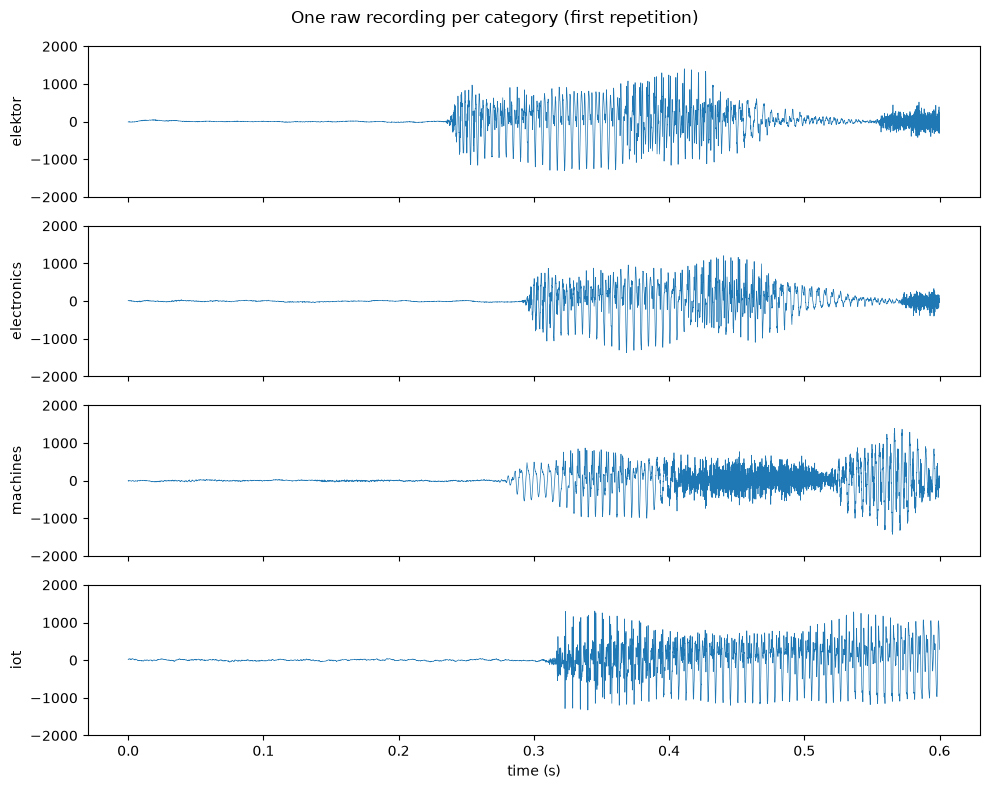

In [4]:
fig, axes = plt.subplots(len(CATEGORIES), 1, figsize=(10, 8), sharex=True, sharey=True)
t = np.arange(NUM_SAMPLES) / SAMPLE_RATE_HZ

for ax, category in zip(axes, CATEGORIES):
    example = next(r for r in recordings if r["category"] == category and r["recording_id"].endswith("_01"))
    ax.plot(t, example["samples"], linewidth=0.5)
    ax.set_ylabel(category)
    ax.set_ylim(-2000, 2000)

axes[-1].set_xlabel("time (s)")
fig.suptitle("One raw recording per category (first repetition)")
fig.tight_layout()
plt.show()

Two things should already be visible. First, most of each 0.6 second
clip is quiet: the word does not fill the recording window, there is a
silent margin before and after it. Second, a single number describing the
whole clip, its overall mean or standard deviation, would average the loud
part together with that silence and say very little about the sound
itself. That is the problem windowing solves: instead of one statistic for
the whole recording, compute one statistic *per short window* and look at
how it changes over time.

## 3. Windowing: from one long signal to a series of short ones

A window is a short, fixed-length slice of the signal. Windowing means
sliding that slice across the recording, a fixed number of samples at a
time (the *hop*), and computing something over each slice rather than over
the whole recording at once. This is the same idea Chapter 6 introduces for
event streams (grouping a continuous stream into finite intervals to make
it possible to process) applied to a single audio recording instead of a
stream of events.

This notebook uses:

- **window length**: 400 samples, 25 ms at 16 kHz;
- **hop length**: 200 samples, 50% overlap between consecutive windows.

25 ms is long enough to contain several cycles of a typical speech
frequency (voiced speech is usually well under 500 Hz at the fundamental),
short enough that a window sits entirely inside either the quiet part or
the loud part of the clip, rarely straddling both.

In [5]:
WINDOW_LEN = 400   # samples, 25 ms at 16 kHz
HOP_LEN = 200      # samples, 50% overlap


def make_windows(samples: np.ndarray, window_len: int = WINDOW_LEN, hop_len: int = HOP_LEN) -> np.ndarray:
    """Returns an array of shape (n_windows, window_len)."""
    n_windows = 1 + (len(samples) - window_len) // hop_len
    starts = np.arange(n_windows) * hop_len
    return np.stack([samples[s : s + window_len] for s in starts])


example = next(r for r in recordings if r["category"] == "elektor" and r["recording_id"].endswith("_01"))
windows = make_windows(example["samples"])
print(f"{len(example['samples'])} samples -> {windows.shape[0]} windows of {windows.shape[1]} samples each")

9600 samples -> 47 windows of 400 samples each


### Per-window features, computed without any model

Two features, both plain descriptive statistics over one window's samples,
no fitting involved:

- **RMS energy** — the root-mean-square amplitude of the window. This is
  loudness: near zero in a silent window, large while the word is being
  spoken. \(\text{RMS} = \sqrt{\frac{1}{N}\sum_{i=1}^{N} x_i^2}\), the
  same definition Chapter 6 uses for vibration windows, applied to sound
  instead of acceleration.
- **Zero-crossing rate (ZCR)** — the fraction of consecutive sample pairs
  that change sign. A low-frequency, tonal sound crosses zero rarely; a
  noisy, broadband sound crosses zero often. It is one of the oldest, and
  simplest, ways to describe pitch and noisiness without an FFT.

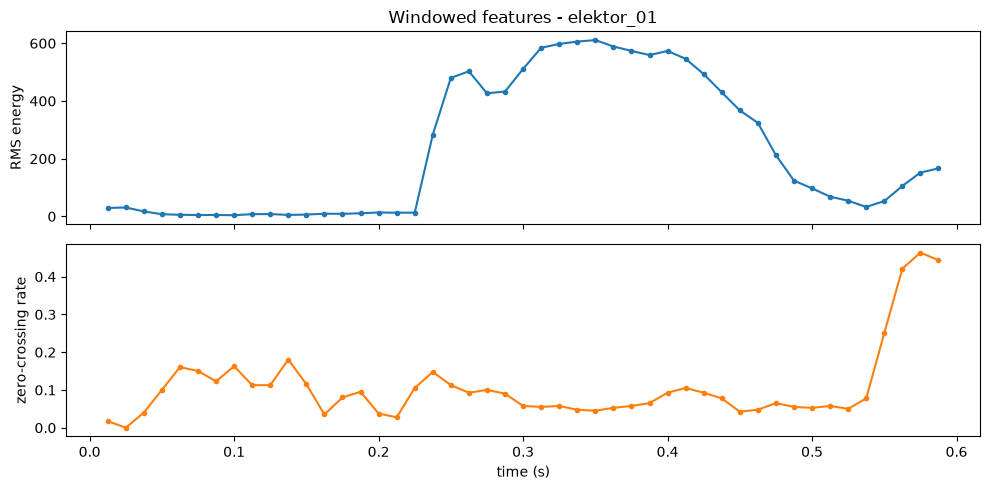

In [6]:
def rms(window: np.ndarray) -> float:
    return float(np.sqrt(np.mean(window.astype(np.float64) ** 2)))


def zero_crossing_rate(window: np.ndarray) -> float:
    signs = np.sign(window)
    signs[signs == 0] = 1  # a zero sample does not count as its own crossing
    crossings = np.count_nonzero(np.diff(signs) != 0)
    return crossings / (len(window) - 1)


rms_per_window = np.array([rms(w) for w in windows])
zcr_per_window = np.array([zero_crossing_rate(w) for w in windows])

window_times = (np.arange(len(windows)) * HOP_LEN + WINDOW_LEN / 2) / SAMPLE_RATE_HZ

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax1.plot(window_times, rms_per_window, marker=".")
ax1.set_ylabel("RMS energy")
ax1.set_title(f"Windowed features - {example['recording_id']}")
ax2.plot(window_times, zcr_per_window, marker=".", color="tab:orange")
ax2.set_ylabel("zero-crossing rate")
ax2.set_xlabel("time (s)")
fig.tight_layout()
plt.show()

Compare this to the single raw waveform plot above. The RMS curve
makes the loud part of the recording, the word itself, into an obvious
bump against a quiet baseline. That bump is now something the rest of this
notebook can measure precisely: where it starts, how tall it is, how long
it lasts. None of that was a usable number before windowing.

## 4. One feature summary per recording

The plot above is for one recording. To compare categories, every
recording needs to collapse down to a small number of features, still
computed from the windows, still without any fitting:

- `peak_rms` — the loudest window's RMS. How loud the word got.
- `active_frac` — the fraction of windows whose RMS exceeds a fixed
  fraction of the recording's own peak. How much of the clip the word
  actually filled, a rough proxy for its duration.
- `mean_zcr_active` — the average zero-crossing rate, restricted to the
  active windows (the quiet windows' ZCR is mostly noise and would dilute
  this). How tonal or noisy the word sounded while it was being said.

In [7]:
ACTIVE_THRESHOLD_FRAC = 0.3  # a window counts as "active" above 30% of this recording's own peak RMS


def summarize_recording(samples: np.ndarray) -> dict:
    windows = make_windows(samples)
    rms_vals = np.array([rms(w) for w in windows])
    zcr_vals = np.array([zero_crossing_rate(w) for w in windows])

    peak = float(rms_vals.max())
    active = rms_vals > (ACTIVE_THRESHOLD_FRAC * peak)
    active_frac = float(active.mean())
    mean_zcr_active = float(zcr_vals[active].mean()) if active.any() else float("nan")

    return {
        "peak_rms": peak,
        "active_frac": active_frac,
        "mean_zcr_active": mean_zcr_active,
    }


summary_rows = []
for r in recordings:
    features = summarize_recording(r["samples"])
    summary_rows.append({"category": r["category"], "recording_id": r["recording_id"], **features})

summary = pd.DataFrame(summary_rows)
summary

,category,recording_id,peak_rms,active_frac,mean_zcr_active
0,elektor,elektor_01,611.061836,0.425532,0.075313
1,elektor,elektor_02,608.037402,0.425532,0.073434
2,elektor,elektor_03,598.543384,0.425532,0.075313
3,elektor,elektor_04,589.970487,0.404255,0.072286
4,elektor,elektor_05,586.379065,0.404255,0.072814
5,electronics,electronics_01,612.810662,0.382979,0.069758
6,electronics,electronics_02,589.707985,0.382979,0.070593
7,electronics,electronics_03,598.295406,0.382979,0.068922
8,electronics,electronics_04,582.431758,0.382979,0.068922
9,electronics,electronics_05,576.583877,0.382979,0.069618


### Do the categories separate, once windowed?

Grouped summary statistics first, the same `groupby().describe()` habit
Chapter 7 uses for label-conditioned EDA on tabular data, applied to these
engineered features instead of raw sensor columns.

In [8]:
summary.groupby("category")[["peak_rms", "active_frac", "mean_zcr_active"]].agg(["mean", "std"])

peak_rms            active_frac           mean_zcr_active  \
                   mean        std        mean       std            mean   
category                                                                   
electronics  591.965938  14.205381    0.382979  0.000000        0.069563   
elektor      598.798435  10.816515    0.417021  0.011654        0.073832   
iot          631.235255   9.536337    0.519149  0.019030        0.076004   
machines     707.662266   8.987973    0.459574  0.028546        0.247007   

                       
                  std  
category               
electronics  0.000693  
elektor      0.001412  
iot          0.002666  
machines     0.008396

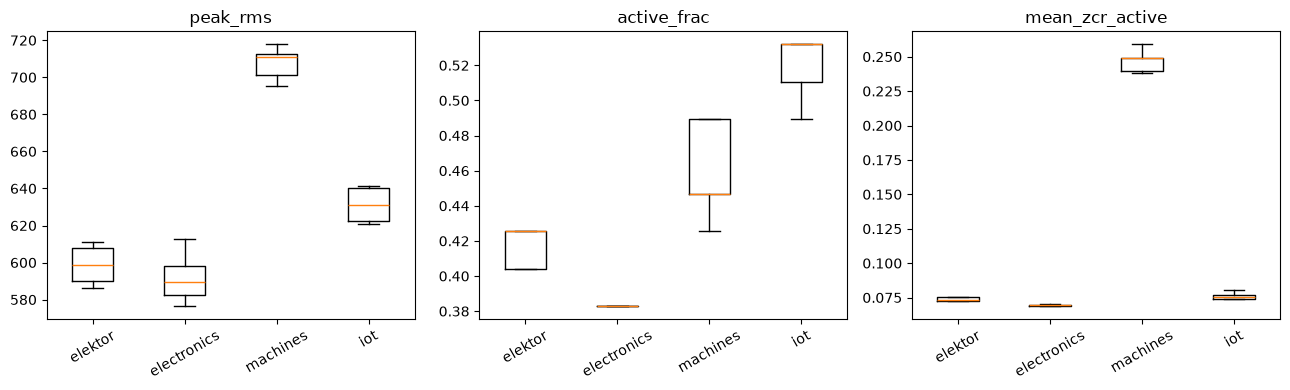

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, feature in zip(axes, ["peak_rms", "active_frac", "mean_zcr_active"]):
    data = [summary.loc[summary["category"] == c, feature].to_numpy() for c in CATEGORIES]
    ax.boxplot(data)
    ax.set_xticks(range(1, len(CATEGORIES) + 1), CATEGORIES)
    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

Read these three box plots the way Chapter 7 reads a label-conditioned
distribution plot: do a feature's boxes for different categories overlap,
or sit apart? A feature whose boxes barely overlap across categories is
doing real separating work. A feature whose boxes all overlap is not
telling the categories apart on its own, whatever it might combine with.
Five recordings per category is a small sample. This is enough to see
whether the idea works on real hardware, not enough to claim a precise,
generalizable number for any one feature.

## 5. Distinguishing the categories without machine learning

Nothing below is fitted, trained, or optimized. It is one more descriptive
statistic: each category's centroid, the mean of its own feature vectors,
computed directly from the numbers above. A new recording is assigned to
whichever centroid it sits closest to, by ordinary Euclidean distance.
There is no loss function, no iteration, and no train/test split, because
there is no parameter being learned, only an average being read off the
same table already printed above.

To keep this an honest self-check rather than a trick, each recording's
own values are excluded when computing its category's centroid
(leave-one-out): a recording is never allowed to be compared against a
centroid it contributed to.

In [10]:
FEATURES = ["peak_rms", "active_frac", "mean_zcr_active"]

feature_matrix = summary[FEATURES].to_numpy(dtype=np.float64)
# Each feature has a different scale (peak_rms is in the hundreds,
# active_frac is between 0 and 1) - z-score each column so the distance
# calculation below does not just measure whichever feature has the
# largest raw numbers. The mean/std used are the whole table's own,
# a fixed rescaling, not a fitted parameter.
feature_mean = feature_matrix.mean(axis=0)
feature_std = feature_matrix.std(axis=0)
scaled = (feature_matrix - feature_mean) / feature_std

categories_arr = summary["category"].to_numpy()


def nearest_centroid_loo(index: int) -> str:
    other = np.delete(scaled, index, axis=0)
    other_categories = np.delete(categories_arr, index)
    distances = {}
    for category in CATEGORIES:
        group = other[other_categories == category]
        centroid = group.mean(axis=0)
        distances[category] = np.linalg.norm(scaled[index] - centroid)
    return min(distances, key=distances.get)


predicted = [nearest_centroid_loo(i) for i in range(len(summary))]
summary["nearest_centroid"] = predicted
summary["correct"] = summary["category"] == summary["nearest_centroid"]
summary[["category", "recording_id", "nearest_centroid", "correct"]]

,category,recording_id,nearest_centroid,correct
0,elektor,elektor_01,elektor,True
1,elektor,elektor_02,elektor,True
2,elektor,elektor_03,elektor,True
3,elektor,elektor_04,elektor,True
4,elektor,elektor_05,electronics,False
5,electronics,electronics_01,electronics,True
6,electronics,electronics_02,electronics,True
7,electronics,electronics_03,electronics,True
8,electronics,electronics_04,electronics,True
9,electronics,electronics_05,electronics,True


In [11]:
accuracy = summary["correct"].mean()
print(f"leave-one-out nearest-centroid agreement: {summary['correct'].sum()}/{len(summary)} ({accuracy:.0%})")

confusion = pd.crosstab(summary["category"], summary["nearest_centroid"], dropna=False)
confusion = confusion.reindex(index=CATEGORIES, columns=CATEGORIES, fill_value=0)
confusion

leave-one-out nearest-centroid agreement: 19/20 (95%)


nearest_centroid,elektor,electronics,machines,iot
category,,,,
elektor,4,1,0,0
electronics,0,5,0,0
machines,0,0,5,0
iot,0,0,0,5


This confusion table is the same kind of table a trained classifier's
evaluation would produce, but nothing here was trained. Every number in it
comes from windowed, descriptive statistics: RMS and zero-crossing rate
computed directly from the samples, category centroids computed directly
from those features. A small, imbalanced result here (five recordings per
category is not enough to claim a precise error rate) is still real
evidence about whether the *features* separate the categories, which is
exactly the question EDA is supposed to answer before any modeling
decision gets made.

## Key observations

- **A raw waveform alone rarely answers the question.** Most of each
  0.6-second recording is silence around the spoken word; a single
  clip-level statistic mixes that silence into whatever it reports.
- **Windowing turns one long signal into a series of short, comparable
  measurements.** RMS energy makes the word's position and loudness
  visible as a clear bump against a quiet baseline; zero-crossing rate adds
  a second, independent view of the same window.
- **Two or three windowed features, summarized per recording, separated
  these four categories using only their own group means**, computed with
  a leave-one-out check, no fitted model anywhere in the pipeline.
- **This is still EDA, not a deployment-ready pipeline.** Five recordings
  per category is enough to see the idea work on real hardware; it is not
  enough data to trust a precise accuracy number, and nothing here has
  been tested against sounds recorded in a different room, at a different
  volume, or by a different speaker.